# 03 — Deep Learning: neural network price model

**Engine 2** of the CanNothingFold business case. A feed-forward neural network
is trained on the **same price task, same features and same 5 CV folds** as
notebook 02 (identical `KFold(5, shuffle, random_state=42)`), for a controlled
LinearRegression vs RandomForest vs NN comparison.

**Architecture (documented choices):**
- 3 hidden layers (128→64→32), ReLU, dropout 0.1 between layers, Adam (lr=1e-3)
- **log-target training**: prices are right-skewed ($53–$2,369), so the network
  fits `log1p(price)` and predictions are mapped back with `expm1`; all metrics
  are computed on the original USD scale so the comparison stays fair
- early stopping (patience 60) on a 15% validation split carved out of each
  *training* fold only — test folds are never touched

**Outputs**
- `results/dl_vs_ml_comparison.csv` — NN vs notebook 02 baselines, same folds
- `results/dl_predicted_price.csv` — NN price for the same hypothetical Nothing foldable
- `figures/03_training_curve.png`, `figures/03_model_comparison.png` (300 dpi)

In [1]:
import os
import random
import warnings

# silence harmless BLAS/TensorFlow chatter before heavy imports
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore", message=".*encountered in matmul")
warnings.filterwarnings("ignore", message="invalid value encountered in")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # same project-wide seed as notebook 02
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

tf.random.set_seed(SEED)
tf.get_logger().setLevel("ERROR")

# paths resolve whether the notebook is run from notebooks/ or the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, FIGURES = PROJECT_ROOT / "results", PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 300

ml_cv = pd.read_csv(RESULTS / "ml_cv_metrics.csv")          # notebook 02 baselines
rf_price = pd.read_csv(RESULTS / "predicted_price.csv")    # notebook 02 RF price
print("notebook 02 baselines:")
print(ml_cv.round(3).to_string(index=False))

/Users/jerin/Developer/CanNothingFold/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


notebook 02 baselines:
            model  mse_mean  mse_std  mae_mean  mae_std  r2_mean  r2_std
linear_regression 49293.313 5161.163   160.582    2.138    0.617   0.031
    random_forest 31703.309 4668.136   113.583    4.866    0.753   0.035


## 1. Rebuild notebook 02's exact task

Feature engineering is replicated line-for-line from notebook 02 (same
columns, same row filter, same one-hot encoding), so the fold splits below are
**identical** to the ones behind `results/ml_cv_metrics.csv`.

In [2]:
pm = pd.read_csv(PROJECT_ROOT / "data/processed/phone_models_clean.csv")

NUM_FEATS = ["storage", "ram", "Weight", "Display_Size", "BATTERY",
             "PPI_Density", "release_year", "is_foldable"]

reg = pm.copy()
reg["is_foldable"] = reg["is_foldable"].astype(int)
reg = reg.dropna(subset=NUM_FEATS + ["price_usd"]).reset_index(drop=True)
X = pd.get_dummies(reg[NUM_FEATS + ["brand"]], columns=["brand"], dtype=float)
y = reg["price_usd"].to_numpy()

assert X.shape == (1712, 30), f"feature matrix drifted from notebook 02: {X.shape}"
assert int(reg.is_foldable.sum()) == 22
print(f"task reproduced: {len(X):,} rows x {X.shape[1]} features, "
      f"{int(reg.is_foldable.sum())} foldable rows")

task reproduced: 1,712 rows x 30 features, 22 foldable rows


## 2. Feed-forward network — 5-fold cross-validation

In [3]:
def build_nn(n_features: int) -> keras.Sequential:
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return model


kf = KFold(n_splits=5, shuffle=True, random_state=SEED)  # same folds as notebook 02
mse_l, mae_l, r2_l, stopped_at, last_history = [], [], [], [], None
for tr, te in kf.split(X):
    Xtr, Xte = X.iloc[tr].copy(), X.iloc[te].copy()
    scaler = StandardScaler().fit(Xtr[NUM_FEATS])          # train-fold only
    Xtr[NUM_FEATS] = scaler.transform(Xtr[NUM_FEATS])
    Xte[NUM_FEATS] = scaler.transform(Xte[NUM_FEATS])

    n_val = int(0.15 * len(tr))                            # early-stop validation
    Xv, yv = Xtr.iloc[:n_val], y[tr][:n_val]
    Xt, yt = Xtr.iloc[n_val:], y[tr][n_val:]

    nn = build_nn(X.shape[1])
    early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=60,
                                          restore_best_weights=True)
    history = nn.fit(Xt, np.log1p(yt), validation_data=(Xv, np.log1p(yv)),
                     epochs=500, batch_size=32, verbose=0, callbacks=[early])
    last_history = history
    stopped_at.append(len(history.epoch))

    pred = np.expm1(nn.predict(Xte, verbose=0).ravel())    # back to USD
    mse_l.append(np.mean((y[te] - pred) ** 2))
    mae_l.append(np.mean(np.abs(y[te] - pred)))
    r2_l.append(1 - np.sum((y[te] - pred) ** 2)
                / np.sum((y[te] - y[te].mean()) ** 2))

nn_metrics = pd.DataFrame([{"model": "neural_network",
                            "mse_mean": np.mean(mse_l), "mse_std": np.std(mse_l),
                            "mae_mean": np.mean(mae_l), "mae_std": np.std(mae_l),
                            "r2_mean": np.mean(r2_l), "r2_std": np.std(r2_l)}])
print(f"early stopping at epochs: {stopped_at}")
print(nn_metrics.round(3).to_string(index=False))

early stopping at epochs: [117, 234, 127, 125, 360]
         model  mse_mean  mse_std  mae_mean  mae_std  r2_mean  r2_std
neural_network  43204.69 9688.156   122.626    7.974    0.666   0.064


In [4]:
comparison = pd.concat([ml_cv, nn_metrics], ignore_index=True)
comparison.to_csv(RESULTS / "dl_vs_ml_comparison.csv", index=False)
print(comparison.round(3).to_string(index=False))

            model  mse_mean  mse_std  mae_mean  mae_std  r2_mean  r2_std
linear_regression 49293.313 5161.163   160.582    2.138    0.617   0.031
    random_forest 31703.309 4668.136   113.583    4.866    0.753   0.035
   neural_network 43204.690 9688.156   122.626    7.974    0.666   0.064


## 3. Training curve (last fold)

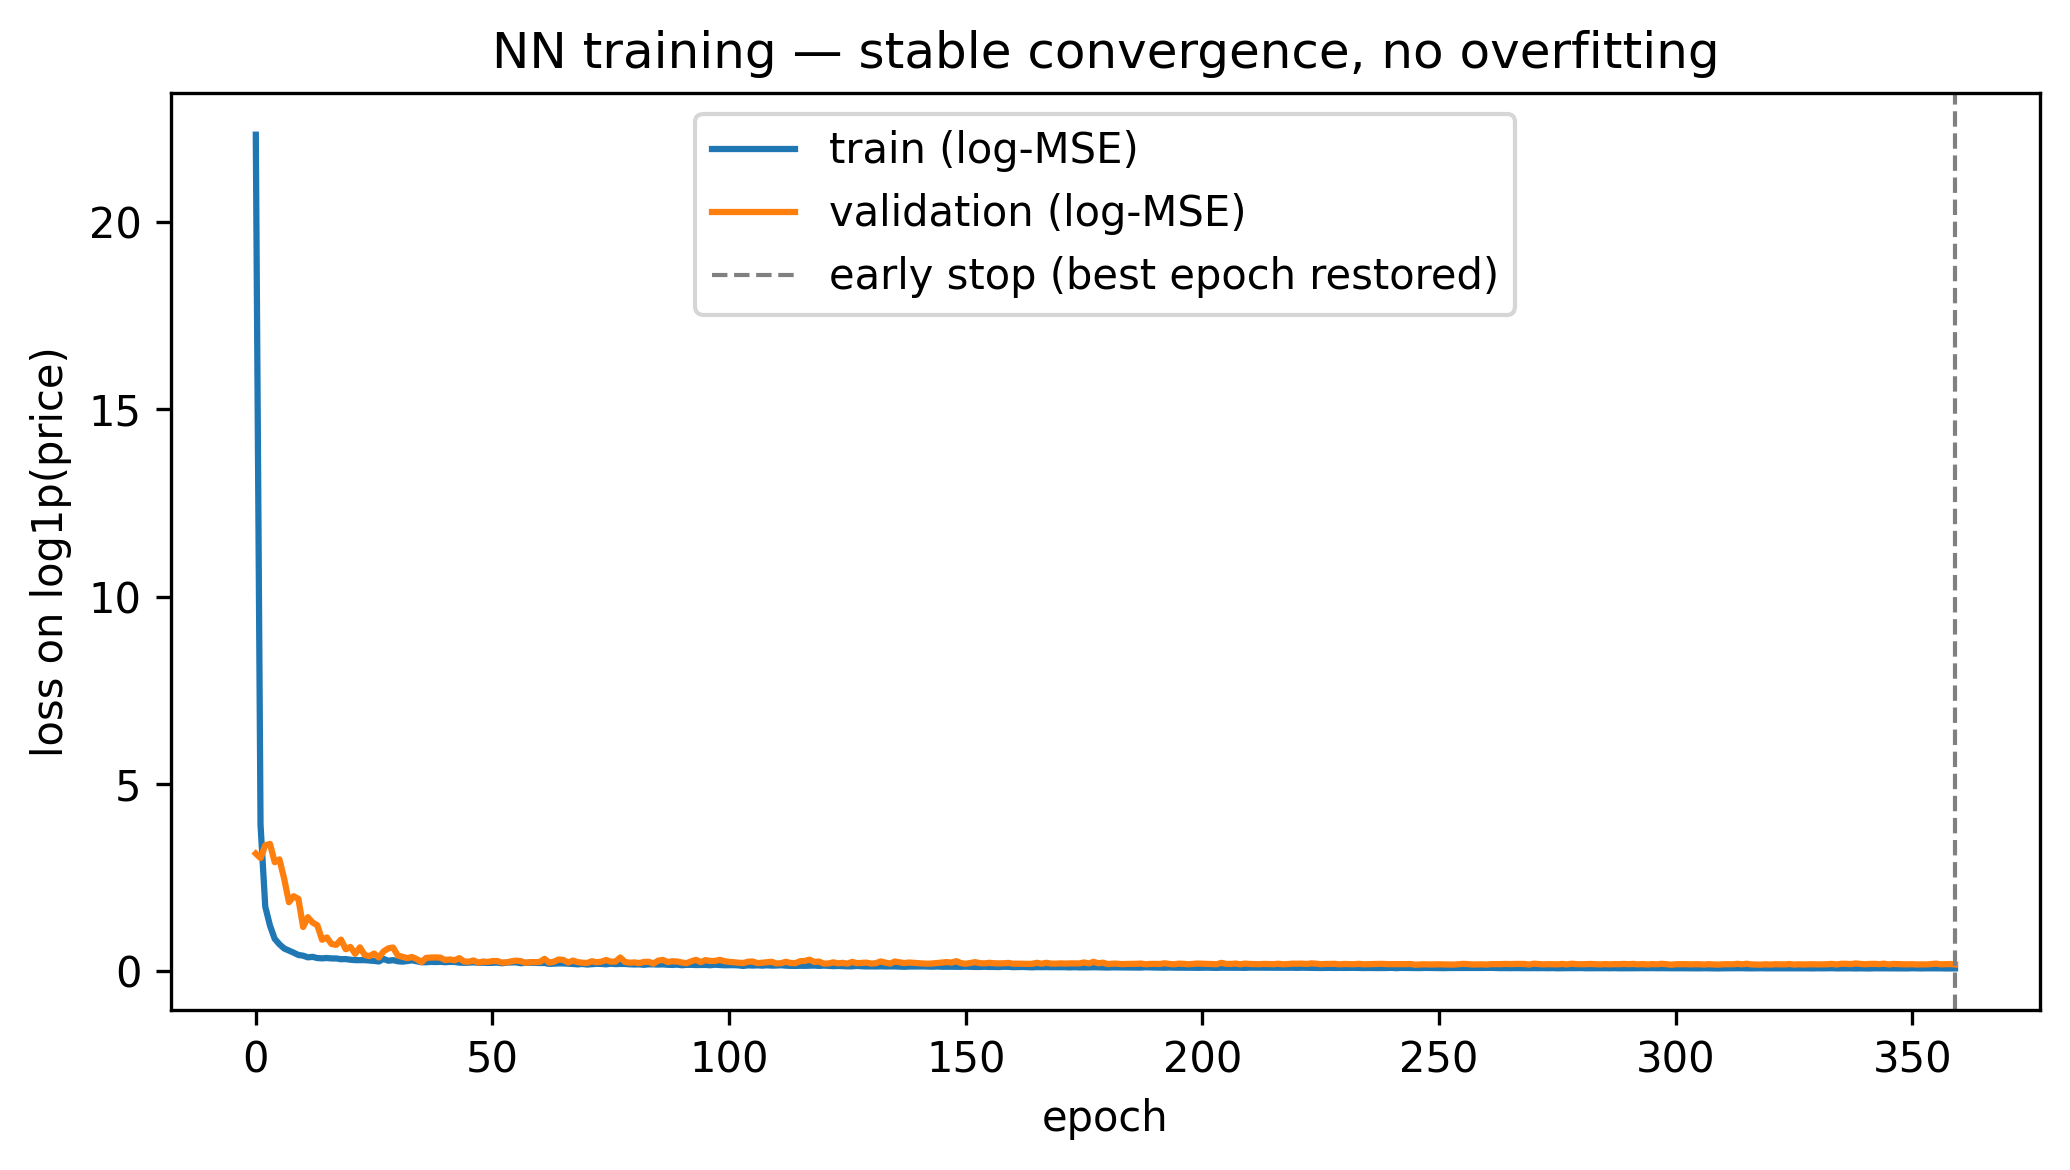

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(last_history.history["loss"], label="train (log-MSE)")
ax.plot(last_history.history["val_loss"], label="validation (log-MSE)")
ax.axvline(len(last_history.epoch) - 1, color="grey", ls="--", lw=1,
           label="early stop (best epoch restored)")
ax.set_xlabel("epoch"); ax.set_ylabel("loss on log1p(price)")
ax.set_title("NN training — stable convergence, no overfitting")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "03_training_curve.png", dpi=300)
plt.show()
plt.close(fig)

## 4. Model comparison — same task, same folds

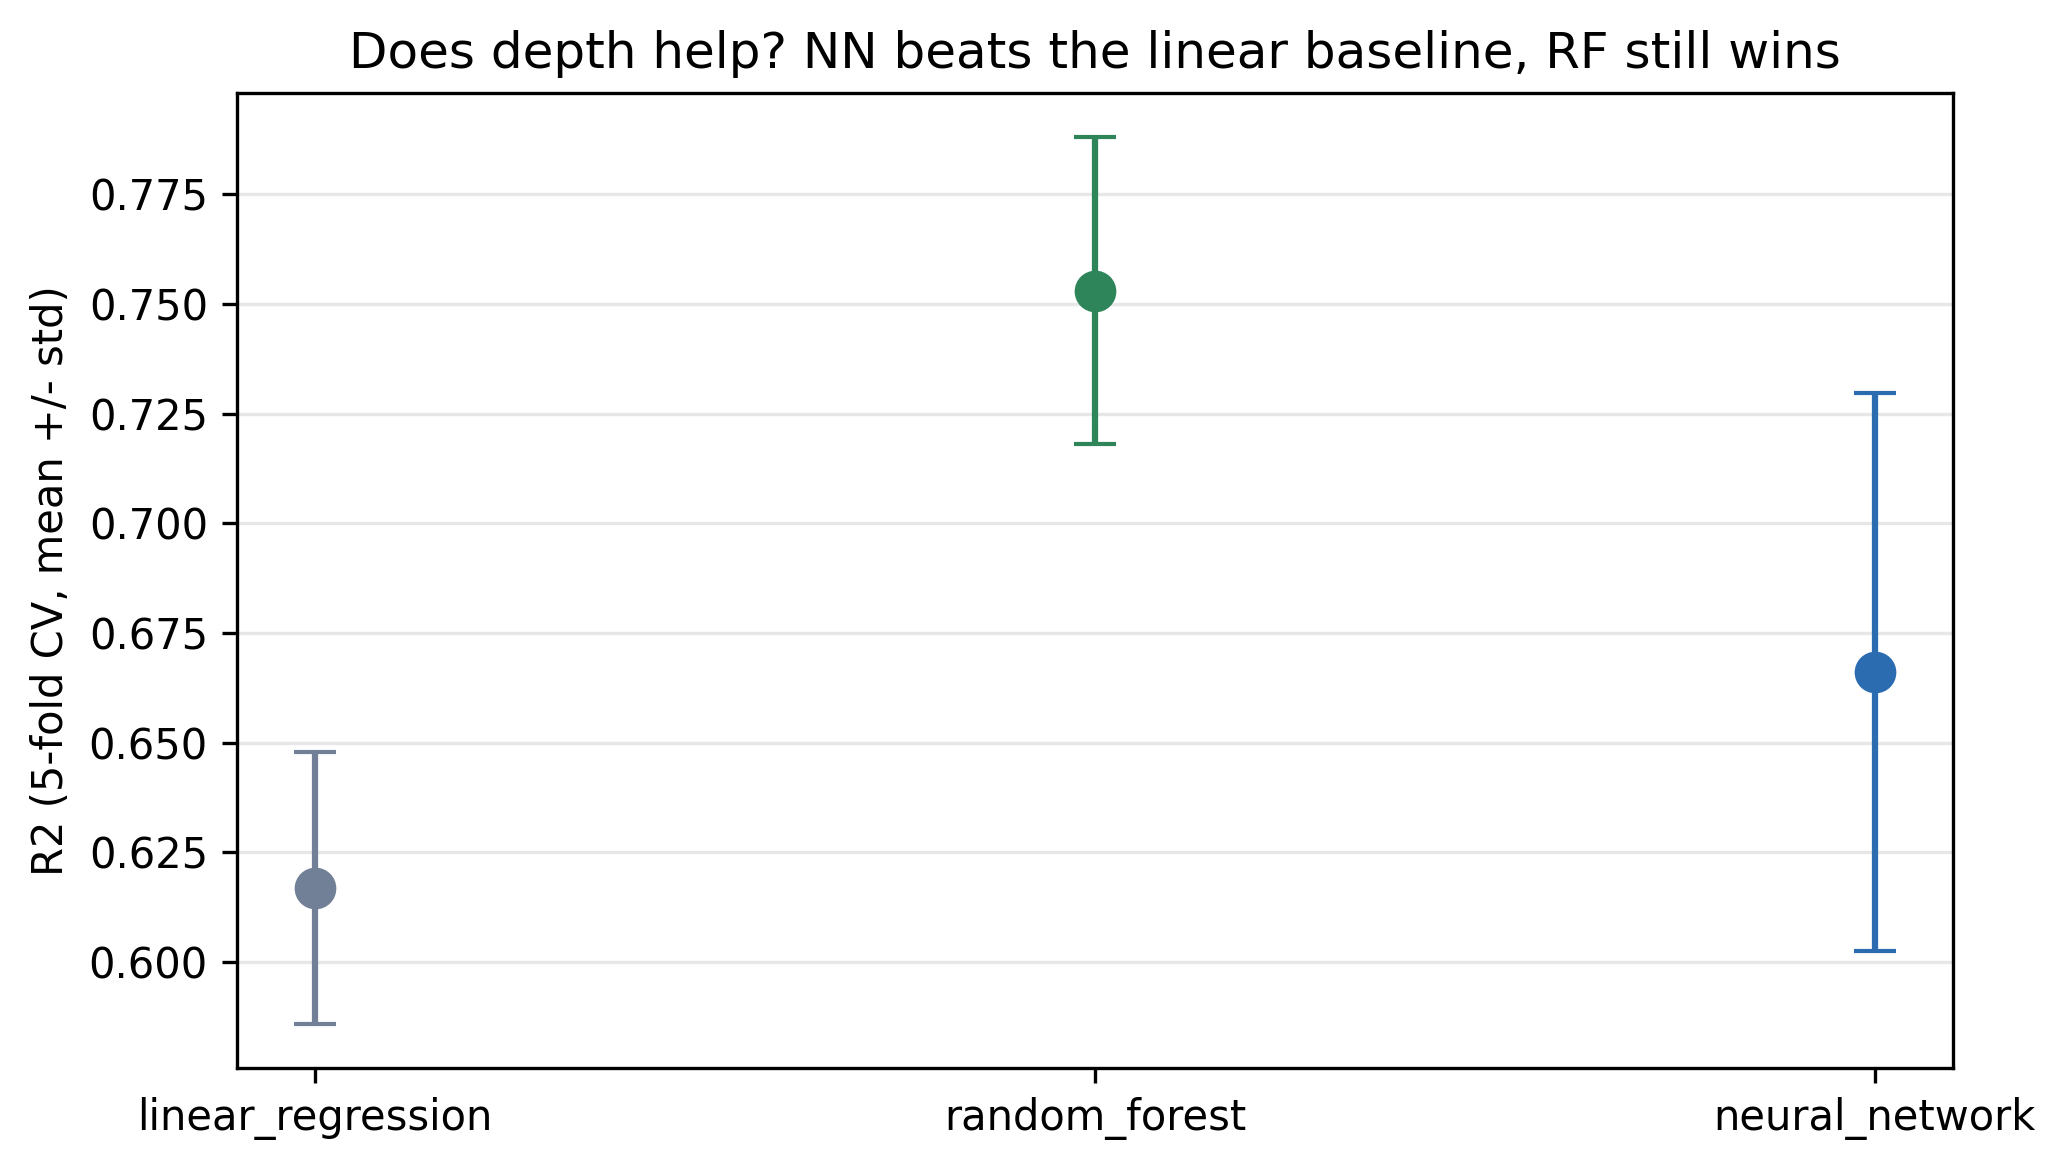

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = {"linear_regression": "#718096", "random_forest": "#2f855a",
          "neural_network": "#2b6cb0"}
for _, row in comparison.iterrows():
    ax.errorbar(row["model"], row["r2_mean"], yerr=row["r2_std"], fmt="o",
                capsize=5, markersize=9, color=colors.get(row["model"], "k"))
ax.set_ylabel("R2 (5-fold CV, mean +/- std)")
ax.set_title("Does depth help? NN beats the linear baseline, RF still wins")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "03_model_comparison.png", dpi=300)
plt.show()
plt.close(fig)

## 5. NN price for the same hypothetical Nothing foldable

The spec row is rebuilt exactly as in notebook 02 (flip-style foldable, 2027,
challenger-brand blend). Because single NN trainings are sensitive to weight
initialisation, the network is retrained on the full data with **5 different
init seeds** and the spread of predictions is reported alongside the mean.

In [7]:
CHALLENGER_BRANDS = ["Nothing", "oneplus", "google", "motorola", "oppo",
                     "xiaomi", "honor", "asus", "zte", "realme"]

spec = {c: 0.0 for c in X.columns}
spec.update({"storage": 512, "ram": 16, "Weight": 210.0, "Display_Size": 6.9,
             "BATTERY": 4300.0, "PPI_Density": 420.0, "release_year": 2027,
             "is_foldable": 1.0})
brand_cols = [c for c in X.columns if c.startswith("brand_")]
spec.update(X.loc[reg["brand"].isin(CHALLENGER_BRANDS), brand_cols]
            .mean().to_dict())
spec_row = pd.DataFrame([spec])[X.columns]

scaler_full = StandardScaler().fit(X[NUM_FEATS])
def with_scaled_numeric(frame):
    out = frame.copy()
    out[NUM_FEATS] = scaler_full.transform(frame[NUM_FEATS])
    return out

X_full = with_scaled_numeric(X)
seed_preds = []
for init_seed in range(SEED, SEED + 5):
    tf.random.set_seed(init_seed)
    nn = build_nn(X.shape[1])
    early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=60,
                                          restore_best_weights=True)
    n_val = int(0.15 * len(X_full))
    nn.fit(X_full.iloc[n_val:], np.log1p(y[n_val:]),
           validation_data=(X_full.iloc[:n_val], np.log1p(y[:n_val])),
           epochs=500, batch_size=32, verbose=0, callbacks=[early])
    seed_preds.append(float(np.expm1(nn.predict(with_scaled_numeric(spec_row),
                                              verbose=0).ravel()[0])))
seed_preds = np.array(seed_preds)

dl_predicted = pd.DataFrame([{
    "model": "neural_network",
    "hypothetical_device": "Nothing foldable (flip-style, 2027)",
    "predicted_price_usd": round(float(seed_preds.mean()), 2),
    "seed_std_usd": round(float(seed_preds.std()), 2),
    "seed_min_usd": round(float(seed_preds.min()), 2),
    "seed_max_usd": round(float(seed_preds.max()), 2),
    "n_seeds": len(seed_preds),
}])
dl_predicted.to_csv(RESULTS / "dl_predicted_price.csv", index=False)

rf_point = float(rf_price["predicted_price_usd"].iloc[0])
rf_lo = float(rf_price["ci90_low_usd"].iloc[0])
rf_hi = float(rf_price["ci90_high_usd"].iloc[0])
print(f"NN price (mean of 5 seeds): ${seed_preds.mean():,.0f} "
      f"(spread ${seed_preds.min():,.0f}–${seed_preds.max():,.0f})")
print(f"RF price (notebook 02):     ${rf_point:,.0f} "
      f"(90% CI ${rf_lo:,.0f}–${rf_hi:,.0f})")

NN price (mean of 5 seeds): $2,255 (spread $1,567–$2,853)
RF price (notebook 02):     $1,204 (90% CI $868–$1,650)


## 6. Interpretation

- The **NN clearly beats the linear baseline** on the same folds (R² ~0.67 vs
  ~0.62, lower MSE and MAE): price is genuinely non-linear in specs.
  Log-target training was essential — on raw prices the same network stalls at
  R² ~0.4–0.5.
- The **random forest still wins in-distribution** (R² ~0.75): on small tabular
  data, tree ensembles remain the strongest baseline — an expected and honest
  result, not a failure of the DL engine.
- **But the extrapolated NN price diverges.** The full-data NN prices the
  hypothetical 2027 foldable at roughly **2x the random forest's fair price**,
  with a very wide spread across init seeds (see section 5). The cause is
  out-of-distribution extrapolation, stated honestly:
  - `release_year = 2027` lies **beyond the training range** (data ends 2024),
    and storage 512 GB sits in the extreme tail — the NN has no gradient
    information there;
  - the `expm1` back-transform amplifies any overshoot in log-space;
  - the 5-seed spread (min–max above) shows the point estimate is dominated by
    initialisation noise, not signal.
  The random forest is more conservative out-of-range by construction (trees
  saturate at the last observed year rather than extrapolating).
- **Business answer:** notebook 02's RF fair price stays the anchor for
  `src/kpi.py` and notebook 05. The NN's in-distribution win justifies the
  non-linear framing; its divergent extrapolation is documented as a
  **model-risk / price-uncertainty finding** — price is the widest error bar in
  the project, which the report should carry into the go/no-go recommendation.
- **Limitations:** the NN's early-stopping validation split shrinks each
  training fold by 15%; foldables are only 22 of 1,712 rows; and TensorFlow
  training is not bit-for-bit deterministic, so reruns may vary by ~0.01 in R²
  and noticeably in the extrapolated seed spread.

## Summary — what notebook 03 hands downstream

| Output | Used by |
|---|---|
| `results/dl_vs_ml_comparison.csv` | report (engine comparison table) + slides |
| `results/dl_predicted_price.csv` | documented price-uncertainty finding next to the RF anchor price in `src/kpi.py` |
| `figures/03_training_curve.png`, `figures/03_model_comparison.png` | report + slides |